# Exercise: Classify Wines with a Tree vs. a Forest 🍷

**Scenario:** A winery ran a chemical analysis on 178 bottles of wine, each grown by one of **three different cultivars** (growers). From 13 chemical measurements (alcohol, acidity, colour intensity, and so on), can you predict **which cultivar** a wine came from?

This is a **multiclass** classification problem (three classes: `0`, `1`, `2`). Your job is to train and compare two models you just learned:

1. A single **Decision Tree**
2. A **Random Forest**
3. Then explore how the **number of trees** (`n_estimators`) affects the forest.

For each model, print a **classification report**. The dataset is `wine.csv`; the target column is `target`.

> Fill in the code under each step (hints are in the comments). No feature scaling needed — tree-based models don't require it!

## Step 1 — Load the data

Read `wine.csv` into `df` and show the first few rows and its shape.

In [5]:
# import pandas as pd
import pandas as pd
# read 'wine.csv' into df
df = pd.read_csv('wine.csv')
# show df.shape and df.head()
print(df.shape)
df.head()

(178, 14)


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


## Step 2 — Get to know the data

- How many wines are in each class? (`df['target'].value_counts()`)
- Any missing values? (`df.isnull().sum().sum()`)

In [9]:
# check the class counts and missing values
print(df.target.value_counts())
print(df.isnull().sum().sum())

target
1    71
0    59
2    48
Name: count, dtype: int64
0


## Step 3 — Features (X) and target (y)

`X` = every column except `target`; `y` = the `target` column.

In [11]:
# X = df.drop(columns='target')
X = df.drop(columns='target')
# y = df['target']
y = df['target']


## Step 4 — Train / test split

Hold back 20% for testing. Use `stratify=y` and `random_state=42`.

In [20]:
# from sklearn.model_selection import train_test_split
from sklearn.model_selection import train_test_split

# X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

print('train:', X_train.shape[0], ' test:', X_test.shape[0])

train: 142  test: 36


## Step 5 — Model 1: Decision Tree

Train a `DecisionTreeClassifier` (`random_state=42`), predict on the test set, and print the classification report (use `target_names=['class_0', 'class_1', 'class_2']`).

*Optional: print train vs test accuracy — is the tree overfitting?*

In [26]:
# from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import DecisionTreeClassifier
# from sklearn.metrics import classification_report
from sklearn.metrics import classification_report
# create + fit the tree, predict, print the classification report
tree = DecisionTreeClassifier(random_state=42).fit(X_train, y_train)

print(classification_report(y_test, tree.predict(X_test), target_names=['class_0', 'class_1', 'class_2']))
print(f'Training accuracy: {round(tree.score(X_train, y_train),3)}')
print(f'Testing accuracy: {round(tree.score(X_test, y_test),3)}')

              precision    recall  f1-score   support

     class_0       1.00      0.92      0.96        12
     class_1       0.88      1.00      0.93        14
     class_2       1.00      0.90      0.95        10

    accuracy                           0.94        36
   macro avg       0.96      0.94      0.95        36
weighted avg       0.95      0.94      0.94        36

Training accuracy: 1.0
Testing accuracy: 0.944


## Step 6 — Model 2: Random Forest

Train a `RandomForestClassifier` (`n_estimators=100`, `random_state=42`), predict, and print its classification report. How does it compare to the single tree?

In [19]:
# from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import RandomForestClassifier
# create + fit the forest, predict, print the classification report
forest = RandomForestClassifier(n_estimators=100, random_state=42).fit(X_train, y_train)

print(classification_report(y_test, forest.predict(X_test), target_names=['class_0', 'class_1', 'class_2']))

              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        12
     class_1       1.00      1.00      1.00        14
     class_2       1.00      1.00      1.00        10

    accuracy                           1.00        36
   macro avg       1.00      1.00      1.00        36
weighted avg       1.00      1.00      1.00        36



## Step 7 — Experiment: how many trees?

Try training the Random Forest with a **couple of different `n_estimators`** values (e.g. `10` and `100`) and print each one's **test accuracy**. What happens as you add more trees — does the accuracy keep climbing, or level off?

1 trees --> 0.917
10 trees --> 1.0
50 trees --> 1.0
100 trees --> 1.0


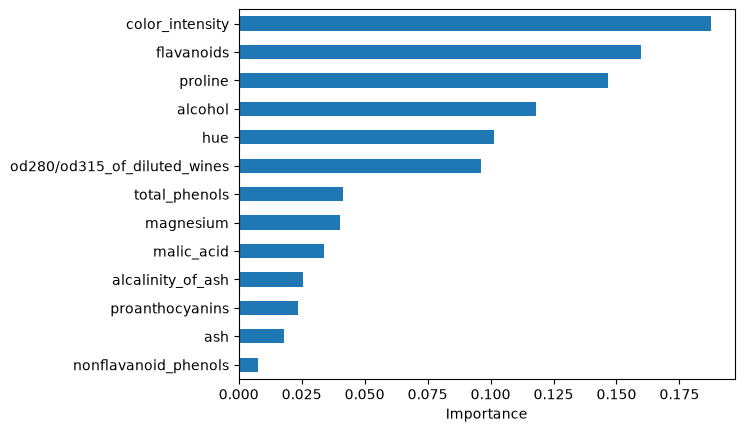

In [24]:
# for n in [10, 100]:
#     rf = RandomForestClassifier(n_estimators=n, random_state=42)
#     rf.fit(X_train, y_train)
#     print(n, 'trees ->', round(rf.score(X_test, y_test), 3))

for n in [1,10,50,100]:
    rf = RandomForestClassifier(n_estimators=n, random_state=42)
    rf.fit(X_train, y_train)
    print(n, 'trees -->', round(rf.score(X_test, y_test),3))

import matplotlib.pyplot as plt
importances = pd.Series(forest.feature_importances_, index=X.columns).sort_values()
importances.plot(kind='barh')
plt.xlabel('Importance')
plt.show()

## Step 8 — Your conclusions

**Questions:**
1. Which model had the higher **test accuracy** — the tree or the forest?
2. Was the single Decision Tree overfitting (train accuracy much higher than test)?
3. Did adding more trees keep improving the accuracy, or did it level off?

## Bonus challenge 🚀

- Plot the Random Forest's **feature importances** (`forest.feature_importances_`) — which chemical measurements best separate the cultivars?
- Try `GridSearchCV` to tune `max_depth` and `n_estimators` together.